# Lab Sheet-V

Crank–Nicolson and Peaceman–Rachford ADI (as in the notes). Derivative BCs: fictitious points + central differences (2nd order); tridiagonal systems by Thomas algorithm. $r=k/h^2$.

## Q1. CN, Neumann BCs

$u_t=u_{xx}$, $u(x,0)=\cos\pi x$, $u_x(0,t)=u_x(1,t)=0$, exact $e^{-\pi^2t}\cos\pi x$  
$A\mathbf U^{n+1}=B\mathbf U^n+\mathbf k^n$, $A=I-\frac r2Q$, $B=I+\frac r2Q$, $Q$: rows $[-2(1+ph),\,2]$, $[1,-2,1]$, $[2,\,-2(1+qh)]$

h = 0.1, k = 0.005, mesh ratio r = k/h^2 = 0.5

--- t = 0.01 ---
     x    U computed       u exact       |error|
  0.00    0.90673367    0.90601806    7.1561e-04
  0.10    0.86235496    0.86167438    6.8059e-04
  0.20    0.73356295    0.73298400    5.7894e-04
  0.30    0.53296468    0.53254405    4.2063e-04
  0.40    0.28019611    0.27997498    2.2114e-04
  0.50    0.00000000    0.00000000    4.1600e-17
  0.60   -0.28019611   -0.27997498    2.2114e-04
  0.70   -0.53296468   -0.53254405    4.2063e-04
  0.80   -0.73356295   -0.73298400    5.7894e-04
  0.90   -0.86235496   -0.86167438    6.8059e-04
  1.00   -0.90673367   -0.90601806    7.1561e-04

--- t = 0.05 ---
     x    U computed       u exact       |error|
  0.00    0.61291282    0.61049803    2.4148e-03
  0.10    0.58291473    0.58061813    2.2966e-03
  0.20    0.49585689    0.49390328    1.9536e-03
  0.30    0.36026112    0.35884174    1.4194e-03
  0.40    0.18940048    0.18865426    7.4621e-04
  0.50   -0.00000000    0.00000000 

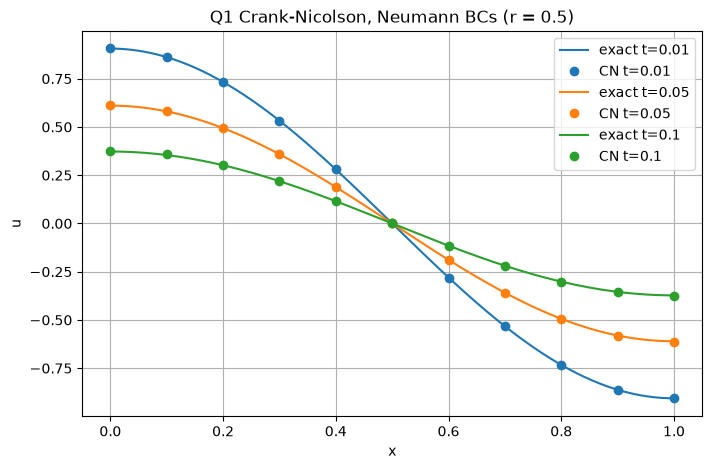

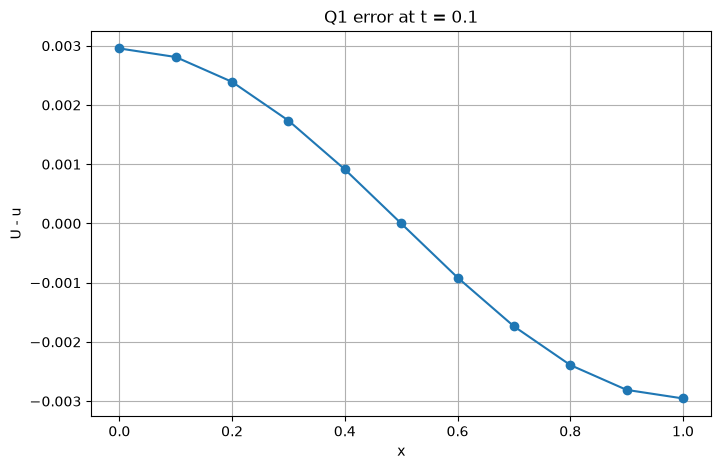

BCs: fictitious points U_{-1} = U_1, U_{M+1} = U_{M-1} (central differences, 2nd order)
|U| is slightly larger than |u|: the discrete decay rate (4/h^2) sin^2(pi h/2) = 9.79 is a bit below pi^2 = 9.87,
so the computed solution decays a little too slowly. Error ~ 7e-4, odd about x = 0.5 like cos(pi x).


In [1]:
import numpy as np
import matplotlib.pyplot as plt


def thomas(A, B, C, F):
    # A[i] u[i-1] + C[i] u[i] + B[i] u[i+1] = F[i]   (Thomas algorithm)
    n = len(C)
    alpha = np.zeros(n + 1)
    beta = np.zeros(n + 1)
    alpha[1] = -B[0]/C[0]
    beta[1] = F[0]/C[0]
    for i in range(1, n):
        den = C[i] + alpha[i]*A[i]
        alpha[i + 1] = -B[i]/den if i < n - 1 else 0
        beta[i + 1] = (F[i] - beta[i]*A[i])/den
    u = np.zeros(n)
    u[n - 1] = beta[n]
    for i in range(n - 2, -1, -1):
        u[i] = alpha[i + 1]*u[i + 1] + beta[i + 1]
    return u


def q_matrix(M, ph, qh):
    # Q from the notes (BCs  u_x - p u = f0 at x=0,  u_x + q u = f1 at x=1, fictitious points removed)
    # row 0: [-2(1+ph), 2],  rows 1..M-1: [1, -2, 1],  row M: [2, -2(1+qh)]
    low = np.ones(M + 1)
    dia = -2*np.ones(M + 1)
    up = np.ones(M + 1)
    low[0] = 0
    up[M] = 0
    up[0] = 2
    low[M] = 2
    dia[0] = -2*(1 + ph)
    dia[M] = -2*(1 + qh)
    return low, dia, up


def q_times(low, dia, up, v):
    w = dia*v
    w[1:] += low[1:]*v[:-1]
    w[:-1] += up[:-1]*v[1:]
    return w


def cn_step(U, r, low, dia, up, kvec):
    # (I - r/2 Q) U^{n+1} = (I + r/2 Q) U^n + k^n
    rhs = U + r/2*q_times(low, dia, up, U) + kvec
    return thomas(-r/2*low, -r/2*up, 1 - r/2*dia, rhs)


def exact(x, t):
    return np.exp(-np.pi**2*t)*np.cos(np.pi*x)


h, k = 0.1, 0.005
r = k/h**2
M = int(round(1/h))
x = np.linspace(0, 1, M + 1)
print(f"h = {h}, k = {k}, mesh ratio r = k/h^2 = {r:.4g}\n")

low, dia, up = q_matrix(M, 0.0, 0.0)      # u_x = 0 at both ends: p = q = 0, f0 = f1 = 0
kvec = np.zeros(M + 1)

U = np.cos(np.pi*x)
t = 0.0
saved = {}
for n in range(1, int(round(0.1/k)) + 1):
    U = cn_step(U, r, low, dia, up, kvec)
    t = n*k
    for ts in [0.01, 0.05, 0.1]:
        if abs(t - ts) < 1e-12:
            saved[ts] = U.copy()

for ts in [0.01, 0.05, 0.1]:
    ex = exact(x, ts)
    print(f"--- t = {ts} ---")
    print(f"{'x':>6}  {'U computed':>12}  {'u exact':>12}  {'|error|':>12}")
    for i in range(M + 1):
        print(f"{x[i]:6.2f}  {saved[ts][i]:12.8f}  {ex[i]:12.8f}  {abs(saved[ts][i] - ex[i]):12.4e}")
    print()

xx = np.linspace(0, 1, 200)
plt.figure(figsize=(8, 5))
for ts in [0.01, 0.05, 0.1]:
    line, = plt.plot(xx, exact(xx, ts), "-", label=f"exact t={ts}")
    plt.plot(x, saved[ts], "o", color=line.get_color(), label=f"CN t={ts}")
plt.xlabel("x")
plt.ylabel("u")
plt.title(f"Q1 Crank-Nicolson, Neumann BCs (r = {r:.4g})")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(x, saved[0.1] - exact(x, 0.1), "o-")
plt.xlabel("x")
plt.ylabel("U - u")
plt.title("Q1 error at t = 0.1")
plt.grid()
plt.show()

print("BCs: fictitious points U_{-1} = U_1, U_{M+1} = U_{M-1} (central differences, 2nd order)")
print("|U| is slightly larger than |u|: the discrete decay rate (4/h^2) sin^2(pi h/2) = 9.79 is a bit below pi^2 = 9.87,")
print("so the computed solution decays a little too slowly. Error ~ 7e-4, odd about x = 0.5 like cos(pi x).")

## Q2. CN, mixed BCs

$u(x,0)=\sin x$, $u_x(0,t)=e^{-t}$, $u_x(1,t)+u(1,t)=(\cos1+\sin1)e^{-t}$, exact $e^{-t}\sin x$  
$p=0,\ f_0=e^{-t}$; $q=1,\ f_1=(\cos1+\sin1)e^{-t}$; $\mathbf k^n=rh\,(-(f_0^n+f_0^{n+1}),0,\dots,0,f_1^n+f_1^{n+1})^T$

h = 0.05, k = 0.05, mesh ratio r = k/h^2 = 20

--- t = 0.1 ---
     x    U computed       u exact       |error|
  0.00   -0.00012232    0.00000000    1.2232e-04
  0.10    0.09022655    0.09033301    1.0646e-04
  0.20    0.17968578    0.17976344    7.7662e-05
  0.30    0.26734695    0.26739774    5.0794e-05
  0.40    0.35233103    0.35236029    2.9253e-05
  0.50    0.43378990    0.43380217    1.2264e-05
  0.60    0.51091177    0.51090964    2.1348e-06
  0.70    0.58292811    0.58291227    1.5842e-05
  0.80    0.64912046    0.64909063    2.9828e-05
  0.90    0.70882613    0.70878350    4.2635e-05
  1.00    0.76144125    0.76139443    4.6818e-05

--- t = 0.3 ---
     x    U computed       u exact       |error|
  0.00   -0.00018313    0.00000000    1.8313e-04
  0.10    0.07379540    0.07395841    1.6301e-04
  0.20    0.14704568    0.14717786    1.3218e-04
  0.30    0.21882242    0.21892675    1.0434e-04
  0.40    0.28840910    0.28848820    7.9104e-05
  0.50    0.35511145    0.35516717    

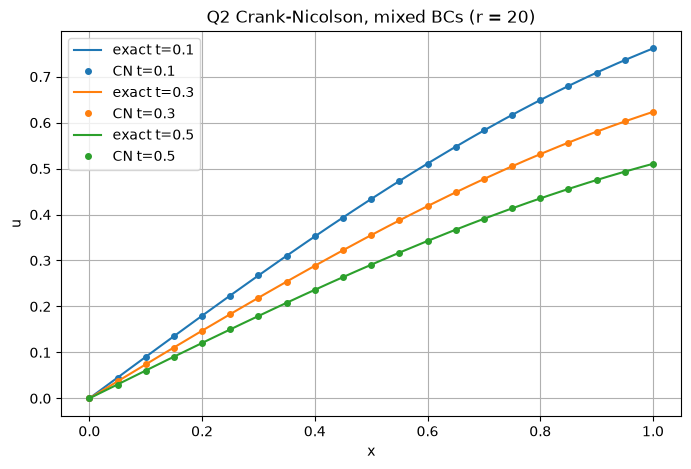

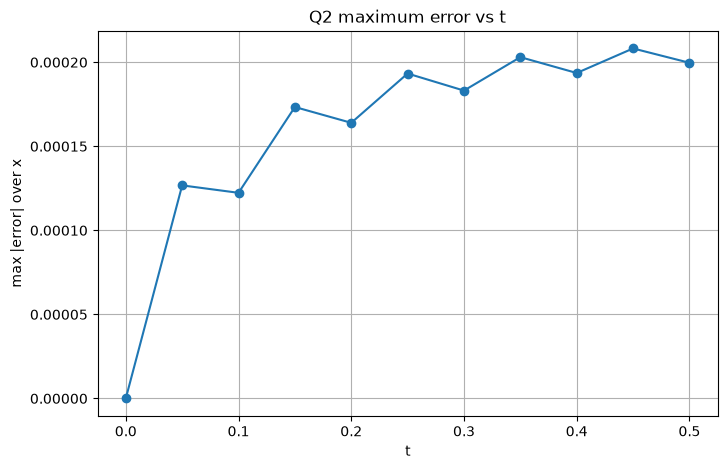

BCs (notes form): u_x - p u = f0 at x=0 with p=0, f0=e^-t;  u_x + q u = f1 at x=1 with q=1
r = 20 is large, but CN is unconditionally stable (p, q >= 0), so the solution stays bounded
max error at t = 0.5: 1.9967e-04


In [2]:
import numpy as np
import matplotlib.pyplot as plt


def thomas(A, B, C, F):
    # A[i] u[i-1] + C[i] u[i] + B[i] u[i+1] = F[i]   (Thomas algorithm)
    n = len(C)
    alpha = np.zeros(n + 1)
    beta = np.zeros(n + 1)
    alpha[1] = -B[0]/C[0]
    beta[1] = F[0]/C[0]
    for i in range(1, n):
        den = C[i] + alpha[i]*A[i]
        alpha[i + 1] = -B[i]/den if i < n - 1 else 0
        beta[i + 1] = (F[i] - beta[i]*A[i])/den
    u = np.zeros(n)
    u[n - 1] = beta[n]
    for i in range(n - 2, -1, -1):
        u[i] = alpha[i + 1]*u[i + 1] + beta[i + 1]
    return u


def q_matrix(M, ph, qh):
    # Q from the notes (BCs  u_x - p u = f0 at x=0,  u_x + q u = f1 at x=1, fictitious points removed)
    # row 0: [-2(1+ph), 2],  rows 1..M-1: [1, -2, 1],  row M: [2, -2(1+qh)]
    low = np.ones(M + 1)
    dia = -2*np.ones(M + 1)
    up = np.ones(M + 1)
    low[0] = 0
    up[M] = 0
    up[0] = 2
    low[M] = 2
    dia[0] = -2*(1 + ph)
    dia[M] = -2*(1 + qh)
    return low, dia, up


def q_times(low, dia, up, v):
    w = dia*v
    w[1:] += low[1:]*v[:-1]
    w[:-1] += up[:-1]*v[1:]
    return w


def cn_step(U, r, low, dia, up, kvec):
    # (I - r/2 Q) U^{n+1} = (I + r/2 Q) U^n + k^n
    rhs = U + r/2*q_times(low, dia, up, U) + kvec
    return thomas(-r/2*low, -r/2*up, 1 - r/2*dia, rhs)


def exact(x, t):
    return np.exp(-t)*np.sin(x)


def f0(t):                       # u_x = f0 at x = 0   (p = 0)
    return np.exp(-t)


def f1(t):                       # u_x + u = f1 at x = 1   (q = 1)
    return (np.cos(1) + np.sin(1))*np.exp(-t)


def solve_q2(h, k, t_end, keep=()):
    M = int(round(1/h))
    x = np.linspace(0, 1, M + 1)
    r = k/h**2
    low, dia, up = q_matrix(M, 0.0, 1.0*h)      # ph = p h = 0,  qh = q h = h
    U = np.sin(x)
    saved = {}
    max_err = [0.0]
    times = [0.0]
    for n in range(int(round(t_end/k))):
        t0, t1 = n*k, (n + 1)*k
        kvec = np.zeros(M + 1)
        kvec[0] = -r*h*(f0(t0) + f0(t1))
        kvec[M] = r*h*(f1(t0) + f1(t1))
        U = cn_step(U, r, low, dia, up, kvec)
        times.append(t1)
        max_err.append(np.abs(U - exact(x, t1)).max())
        for ts in keep:
            if abs(t1 - ts) < 1e-12:
                saved[ts] = U.copy()
    return x, U, saved, np.array(times), np.array(max_err)


h, k = 0.05, 0.05
r = k/h**2
print(f"h = {h}, k = {k}, mesh ratio r = k/h^2 = {r:.4g}\n")

x, U, saved, times, max_err = solve_q2(h, k, 0.5, keep=(0.1, 0.3, 0.5))

for ts in [0.1, 0.3, 0.5]:
    ex = exact(x, ts)
    print(f"--- t = {ts} ---")
    print(f"{'x':>6}  {'U computed':>12}  {'u exact':>12}  {'|error|':>12}")
    for i in range(0, len(x), 2):
        print(f"{x[i]:6.2f}  {saved[ts][i]:12.8f}  {ex[i]:12.8f}  {abs(saved[ts][i] - ex[i]):12.4e}")
    print()

xx = np.linspace(0, 1, 200)
plt.figure(figsize=(8, 5))
for ts in [0.1, 0.3, 0.5]:
    line, = plt.plot(xx, exact(xx, ts), "-", label=f"exact t={ts}")
    plt.plot(x, saved[ts], "o", ms=4, color=line.get_color(), label=f"CN t={ts}")
plt.xlabel("x")
plt.ylabel("u")
plt.title(f"Q2 Crank-Nicolson, mixed BCs (r = {r:.4g})")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(times, max_err, "o-")
plt.xlabel("t")
plt.ylabel("max |error| over x")
plt.title("Q2 maximum error vs t")
plt.grid()
plt.show()

print("BCs (notes form): u_x - p u = f0 at x=0 with p=0, f0=e^-t;  u_x + q u = f1 at x=1 with q=1")
print("r = 20 is large, but CN is unconditionally stable (p, q >= 0), so the solution stays bounded")
print(f"max error at t = 0.5: {max_err[-1]:.4e}")

## Q3. Order and mesh ratio

(a) $k=h$, $h=1/10,\dots,1/80$  (b) $h=1/20$, $r=0.5,1,5,10,50$

(a) k = h
       h         k       r   max err t=0.5    ratio   order
  0.1000    0.1000      10      8.5979e-04
  0.0500    0.0500      20      1.9967e-04     4.31    2.11
  0.0250    0.0250      40      5.0534e-05     3.95    1.98
  0.0125    0.0125      80      1.2712e-05     3.98    1.99
ratio ~4 when h and k are both halved: error = O(h^2 + k^2), 2nd order in x and in t

(b) h = 1/20
     r           k   steps   max err t=0.5
   0.5     0.00125     400      1.7680e-04
     1     0.00250     200      1.7686e-04
     5     0.01250      40      1.7853e-04
    10     0.02500      20      1.8320e-04
    50     0.12500       4      3.3436e-04


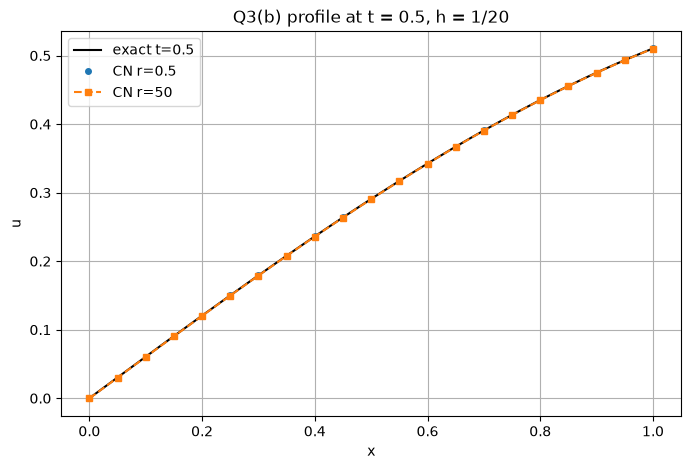


r = 0.5 to 10: error ~1.8e-4, almost unchanged (the O(h^2) space error dominates).
r = 50 (k = 0.125, only 4 steps): error ~3.3e-4, the O(k^2) time error now shows.
CN stays stable for every r (unconditionally stable) and the profile stays smooth here,
because sin x is smooth; large r only costs accuracy in time.


In [3]:
import numpy as np
import matplotlib.pyplot as plt


def thomas(A, B, C, F):
    # A[i] u[i-1] + C[i] u[i] + B[i] u[i+1] = F[i]   (Thomas algorithm)
    n = len(C)
    alpha = np.zeros(n + 1)
    beta = np.zeros(n + 1)
    alpha[1] = -B[0]/C[0]
    beta[1] = F[0]/C[0]
    for i in range(1, n):
        den = C[i] + alpha[i]*A[i]
        alpha[i + 1] = -B[i]/den if i < n - 1 else 0
        beta[i + 1] = (F[i] - beta[i]*A[i])/den
    u = np.zeros(n)
    u[n - 1] = beta[n]
    for i in range(n - 2, -1, -1):
        u[i] = alpha[i + 1]*u[i + 1] + beta[i + 1]
    return u


def q_matrix(M, ph, qh):
    # Q from the notes (BCs  u_x - p u = f0 at x=0,  u_x + q u = f1 at x=1, fictitious points removed)
    # row 0: [-2(1+ph), 2],  rows 1..M-1: [1, -2, 1],  row M: [2, -2(1+qh)]
    low = np.ones(M + 1)
    dia = -2*np.ones(M + 1)
    up = np.ones(M + 1)
    low[0] = 0
    up[M] = 0
    up[0] = 2
    low[M] = 2
    dia[0] = -2*(1 + ph)
    dia[M] = -2*(1 + qh)
    return low, dia, up


def q_times(low, dia, up, v):
    w = dia*v
    w[1:] += low[1:]*v[:-1]
    w[:-1] += up[:-1]*v[1:]
    return w


def cn_step(U, r, low, dia, up, kvec):
    # (I - r/2 Q) U^{n+1} = (I + r/2 Q) U^n + k^n
    rhs = U + r/2*q_times(low, dia, up, U) + kvec
    return thomas(-r/2*low, -r/2*up, 1 - r/2*dia, rhs)


def exact(x, t):
    return np.exp(-t)*np.sin(x)


def f0(t):                       # u_x = f0 at x = 0   (p = 0)
    return np.exp(-t)


def f1(t):                       # u_x + u = f1 at x = 1   (q = 1)
    return (np.cos(1) + np.sin(1))*np.exp(-t)


def solve_q2(h, k, t_end, keep=()):
    M = int(round(1/h))
    x = np.linspace(0, 1, M + 1)
    r = k/h**2
    low, dia, up = q_matrix(M, 0.0, 1.0*h)      # ph = p h = 0,  qh = q h = h
    U = np.sin(x)
    saved = {}
    max_err = [0.0]
    times = [0.0]
    for n in range(int(round(t_end/k))):
        t0, t1 = n*k, (n + 1)*k
        kvec = np.zeros(M + 1)
        kvec[0] = -r*h*(f0(t0) + f0(t1))
        kvec[M] = r*h*(f1(t0) + f1(t1))
        U = cn_step(U, r, low, dia, up, kvec)
        times.append(t1)
        max_err.append(np.abs(U - exact(x, t1)).max())
        for ts in keep:
            if abs(t1 - ts) < 1e-12:
                saved[ts] = U.copy()
    return x, U, saved, np.array(times), np.array(max_err)


# (a) k = h
print("(a) k = h")
print(f"{'h':>8}  {'k':>8}  {'r':>6}  {'max err t=0.5':>14}  {'ratio':>7}  {'order':>6}")
prev = None
for M in [10, 20, 40, 80]:
    h = 1/M
    k = h
    x, U, _, _, _ = solve_q2(h, k, 0.5)
    e = np.abs(U - exact(x, 0.5)).max()
    if prev is None:
        print(f"{h:8.4f}  {k:8.4f}  {k/h**2:6.0f}  {e:14.4e}")
    else:
        print(f"{h:8.4f}  {k:8.4f}  {k/h**2:6.0f}  {e:14.4e}  {prev/e:7.2f}  {np.log2(prev/e):6.2f}")
    prev = e
print("ratio ~4 when h and k are both halved: error = O(h^2 + k^2), 2nd order in x and in t\n")

# (b) h = 1/20, different r
print("(b) h = 1/20")
h = 1/20
print(f"{'r':>6}  {'k':>10}  {'steps':>6}  {'max err t=0.5':>14}")
profiles = {}
for r in [0.5, 1, 5, 10, 50]:
    k = r*h**2
    x, U, _, _, _ = solve_q2(h, k, 0.5)
    profiles[r] = U
    print(f"{r:6g}  {k:10.5f}  {int(round(0.5/k)):6d}  {np.abs(U - exact(x, 0.5)).max():14.4e}")

xx = np.linspace(0, 1, 200)
plt.figure(figsize=(8, 5))
plt.plot(xx, exact(xx, 0.5), "k-", label="exact t=0.5")
plt.plot(x, profiles[0.5], "o", ms=4, label="CN r=0.5")
plt.plot(x, profiles[50], "s--", ms=4, label="CN r=50")
plt.xlabel("x")
plt.ylabel("u")
plt.title("Q3(b) profile at t = 0.5, h = 1/20")
plt.legend()
plt.grid()
plt.show()

print("\nr = 0.5 to 10: error ~1.8e-4, almost unchanged (the O(h^2) space error dominates).")
print("r = 50 (k = 0.125, only 4 steps): error ~3.3e-4, the O(k^2) time error now shows.")
print("CN stays stable for every r (unconditionally stable) and the profile stays smooth here,")
print("because sin x is smooth; large r only costs accuracy in time.")

## Q4. Peaceman–Rachford ADI, Neumann BCs

$u_t=u_{xx}+u_{yy}$, $u(x,y,0)=\cos\pi x\cos\pi y$, exact $e^{-2\pi^2t}\cos\pi x\cos\pi y$  
$(1-\frac r2\delta_x^2)U^{n+1/2}=(1+\frac r2\delta_y^2)U^n$, $(1-\frac r2\delta_y^2)U^{n+1}=(1+\frac r2\delta_x^2)U^{n+1/2}$

===== h = 0.05, k = 0.001, mesh ratio r = 0.4 =====
--- along y = 0.5, t = 0.01 ---
     x     U computed        u exact       |error|
  0.00  -7.285839e-17   5.026371e-17    1.2312e-16
  0.10  -7.979728e-17   4.780363e-17    1.2760e-16
  0.20  -6.591949e-17   4.066420e-17    1.0658e-16
  0.30  -3.642919e-17   2.954427e-17    6.5973e-17
  0.40  -1.734723e-17   1.553234e-17    3.2880e-17
  0.50   5.377530e-18   3.077765e-33    5.3775e-18
  0.60   3.122502e-17  -1.553234e-17    4.6757e-17
  0.70   5.898060e-17  -2.954427e-17    8.8525e-17
  0.80   7.459311e-17  -4.066420e-17    1.1526e-16
  0.90   7.285839e-17  -4.780363e-17    1.2066e-16
  1.00   8.673617e-17  -5.026371e-17    1.3700e-16
max error over the whole grid at t = 0.01: 3.3165e-04

--- along y = 0.5, t = 0.05 ---
     x     U computed        u exact       |error|
  0.00  -2.498002e-16   2.282177e-17    2.7262e-16
  0.10  -2.376571e-16   2.170480e-17    2.5936e-16
  0.20  -1.986258e-16   1.846320e-17    2.1709e-16
  0.30  -1.40

===== h = 0.025, k = 0.00025, mesh ratio r = 0.4 =====
--- along y = 0.5, t = 0.01 ---
     x     U computed        u exact       |error|
  0.00  -3.469447e-18   5.026371e-17    5.3733e-17
  0.10  -1.561251e-17   4.780363e-17    6.3416e-17
  0.20  -1.821460e-17   4.066420e-17    5.8879e-17
  0.30  -1.127570e-17   2.954427e-17    4.0820e-17
  0.40  -9.107298e-18   1.553234e-17    2.4640e-17
  0.50  -4.579427e-18   3.077765e-33    4.5794e-18
  0.60  -8.673617e-19  -1.553234e-17    1.4665e-17
  0.70  -1.734723e-18  -2.954427e-17    2.7810e-17
  0.80   6.071532e-18  -4.066420e-17    4.6736e-17
  0.90   1.734723e-18  -4.780363e-17    4.9538e-17
  1.00   5.204170e-18  -5.026371e-17    5.5468e-17
max error over the whole grid at t = 0.01: 8.3197e-05

--- along y = 0.5, t = 0.05 ---
     x     U computed        u exact       |error|
  0.00  -5.082740e-16   2.282177e-17    5.3110e-16
  0.10  -4.805184e-16   2.170480e-17    5.0222e-16
  0.20  -4.124305e-16   1.846320e-17    4.3089e-16
  0.30  -2

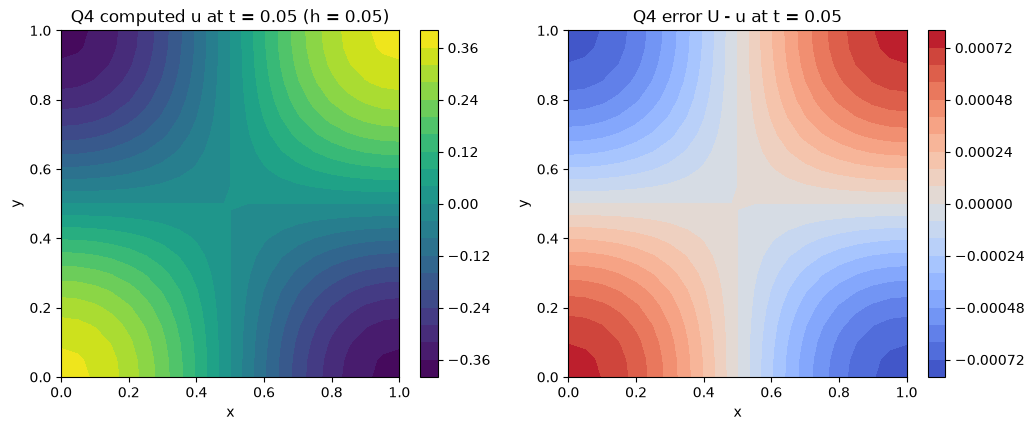

In [4]:
import numpy as np
import matplotlib.pyplot as plt


def thomas(A, B, C, F):
    # A[i] u[i-1] + C[i] u[i] + B[i] u[i+1] = F[i]   (Thomas algorithm)
    n = len(C)
    alpha = np.zeros(n + 1)
    beta = np.zeros(n + 1)
    alpha[1] = -B[0]/C[0]
    beta[1] = F[0]/C[0]
    for i in range(1, n):
        den = C[i] + alpha[i]*A[i]
        alpha[i + 1] = -B[i]/den if i < n - 1 else 0
        beta[i + 1] = (F[i] - beta[i]*A[i])/den
    u = np.zeros(n)
    u[n - 1] = beta[n]
    for i in range(n - 2, -1, -1):
        u[i] = alpha[i + 1]*u[i + 1] + beta[i + 1]
    return u


def q_matrix(M, ph, qh):
    # Q from the notes (BCs  u_x - p u = f0 at x=0,  u_x + q u = f1 at x=1, fictitious points removed)
    # row 0: [-2(1+ph), 2],  rows 1..M-1: [1, -2, 1],  row M: [2, -2(1+qh)]
    low = np.ones(M + 1)
    dia = -2*np.ones(M + 1)
    up = np.ones(M + 1)
    low[0] = 0
    up[M] = 0
    up[0] = 2
    low[M] = 2
    dia[0] = -2*(1 + ph)
    dia[M] = -2*(1 + qh)
    return low, dia, up


def q_times(low, dia, up, v):
    w = dia*v
    w[1:] += low[1:]*v[:-1]
    w[:-1] += up[:-1]*v[1:]
    return w


def d2_along_x(U, low, dia, up):
    W = np.zeros_like(U)
    for j in range(U.shape[1]):
        W[:, j] = q_times(low, dia, up, U[:, j])
    return W


def d2_along_y(U, low, dia, up):
    W = np.zeros_like(U)
    for i in range(U.shape[0]):
        W[i, :] = q_times(low, dia, up, U[i, :])
    return W


def adi_step(U, r, Qx, Qy, bx):
    # Peaceman-Rachford (notes):
    # (1 - r/2 dx^2) U^{n+1/2} = (1 + r/2 dy^2) U^n
    # (1 - r/2 dy^2) U^{n+1}   = (1 + r/2 dx^2) U^{n+1/2}
    # bx = boundary-data part of dx^2 (rows i=0 and i=M), taken at t_{n+1/2}
    lx, dx, ux = Qx
    ly, dy, uy = Qy
    rhs = U + r/2*d2_along_y(U, ly, dy, uy) + r/2*bx
    half = np.zeros_like(U)
    for j in range(U.shape[1]):
        half[:, j] = thomas(-r/2*lx, -r/2*ux, 1 - r/2*dx, rhs[:, j])
    rhs = half + r/2*(d2_along_x(half, lx, dx, ux) + bx)
    new = np.zeros_like(U)
    for i in range(U.shape[0]):
        new[i, :] = thomas(-r/2*ly, -r/2*uy, 1 - r/2*dy, rhs[i, :])
    return new


def exact(x, y, t):
    return np.exp(-2*np.pi**2*t)*np.cos(np.pi*x)*np.cos(np.pi*y)


def solve(h, k, keep):
    M = int(round(1/h))
    x = np.linspace(0, 1, M + 1)
    X, Y = np.meshgrid(x, x, indexing="ij")      # U[i, j] = u(x_i, y_j)
    r = k/h**2
    Q = q_matrix(M, 0.0, 0.0)                     # u_x = 0 and u_y = 0: p = q = 0
    bx = np.zeros((M + 1, M + 1))                 # no boundary data
    U = np.cos(np.pi*X)*np.cos(np.pi*Y)
    saved = {}
    for n in range(1, int(round(max(keep)/k)) + 1):
        U = adi_step(U, r, Q, Q, bx)
        for ts in keep:
            if abs(n*k - ts) < 1e-12:
                saved[ts] = U.copy()
    return x, X, Y, saved


results = {}
for h, k in [(0.05, 0.001), (0.025, 0.00025)]:
    r = k/h**2
    x, X, Y, saved = solve(h, k, (0.01, 0.05))
    results[h] = (x, X, Y, saved)
    M = len(x) - 1
    j = M//2                                      # y = 0.5
    print(f"===== h = {h}, k = {k}, mesh ratio r = {r:.4g} =====")
    for ts in [0.01, 0.05]:
        ex = exact(X, Y, ts)
        print(f"--- along y = 0.5, t = {ts} ---")
        print(f"{'x':>6}  {'U computed':>13}  {'u exact':>13}  {'|error|':>12}")
        step = 1 if h == 0.05 else 2
        for i in range(0, M + 1, 2*step):
            print(f"{x[i]:6.2f}  {saved[ts][i, j]:13.6e}  {ex[i, j]:13.6e}  {abs(saved[ts][i, j] - ex[i, j]):12.4e}")
        print(f"max error over the whole grid at t = {ts}: {np.abs(saved[ts] - ex).max():.4e}\n")

# order
e1 = np.abs(results[0.05][3][0.05] - exact(results[0.05][1], results[0.05][2], 0.05)).max()
e2 = np.abs(results[0.025][3][0.05] - exact(results[0.025][1], results[0.025][2], 0.05)).max()
print(f"max error t=0.05:  h=0.05: {e1:.4e},  h=0.025: {e2:.4e},  ratio = {e1/e2:.2f},  order = {np.log2(e1/e2):.2f}")
print("h halved and k quartered (r fixed = 0.4): ratio ~4 => 2nd order in h (O(h^2 + k^2))")
print("along y = 0.5 the exact solution is 0 (cos(pi/2) = 0), so the values there are ~0\n")

x, X, Y, saved = results[0.05]
U = saved[0.05]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
c0 = ax[0].contourf(X, Y, U, 20, cmap="viridis")
fig.colorbar(c0, ax=ax[0])
ax[0].set_title("Q4 computed u at t = 0.05 (h = 0.05)")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
c1 = ax[1].contourf(X, Y, U - exact(X, Y, 0.05), 20, cmap="coolwarm")
fig.colorbar(c1, ax=ax[1])
ax[1].set_title("Q4 error U - u at t = 0.05")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
plt.show()

## Q5. Peaceman–Rachford ADI, mixed BCs

$u(x,y,0)=\sin x\cos\pi y$, exact $e^{-(1+\pi^2)t}\sin x\cos\pi y$  
$u_x(0,y,t)=e^{-(1+\pi^2)t}\cos\pi y$, $u_x+u=(\cos1+\sin1)e^{-(1+\pi^2)t}\cos\pi y$ at $x=1$, $u_y=0$ at $y=0,1$

h = 0.05, k = 0.002, mesh ratio r = k/h^2 = 0.8

--- along y = 0.0, t = 0.05 ---
     x     U computed        u exact       |error|
  0.00   2.956507e-05   0.000000e+00    2.9565e-05
  0.10   5.804203e-02   5.797563e-02    6.6404e-05
  0.20   1.154876e-01   1.153720e-01    1.1563e-04
  0.30   1.717857e-01   1.716156e-01    1.7010e-04
  0.40   2.263697e-01   2.261445e-01    2.2527e-04
  0.50   2.786921e-01   2.784138e-01    2.7835e-04
  0.60   3.282285e-01   3.279013e-01    3.2725e-04
  0.70   3.744821e-01   3.741125e-01    3.6962e-04
  0.80   4.169875e-01   4.165857e-01    4.0185e-04
  0.90   4.553147e-01   4.548965e-01    4.1822e-04
  1.00   4.890725e-01   4.886621e-01    4.1033e-04

--- along y = 0.0, t = 0.1 ---
     x     U computed        u exact       |error|
  0.00   1.060621e-04   0.000000e+00    1.0606e-04
  0.10   3.379895e-02   3.366782e-02    1.3113e-04
  0.20   6.716946e-02   6.699924e-02    1.7021e-04
  0.30   9.987891e-02   9.966123e-02    2.1767e-04
  0.40   1.315961e-0

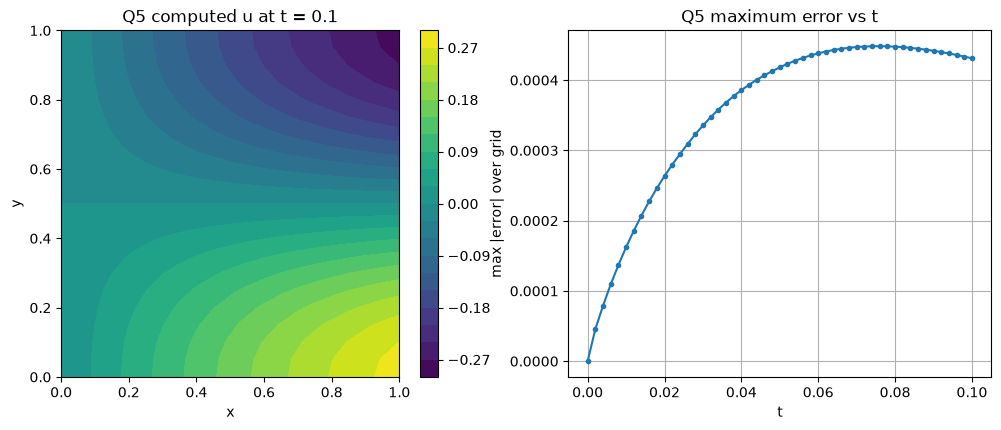

max error at t = 0.1: 4.3111e-04
max error grows up to ~4.5e-4 near t = 0.08, then starts to fall as the solution itself decays
check (not asked): halving h with r fixed gives error ratio ~4 => 2nd order
x-boundary data enters both half-steps at t_{n+1/2}; y-BCs are homogeneous Neumann
along y = 0.5 the exact solution is 0 (cos(pi/2) = 0)


In [5]:
import numpy as np
import matplotlib.pyplot as plt


def thomas(A, B, C, F):
    # A[i] u[i-1] + C[i] u[i] + B[i] u[i+1] = F[i]   (Thomas algorithm)
    n = len(C)
    alpha = np.zeros(n + 1)
    beta = np.zeros(n + 1)
    alpha[1] = -B[0]/C[0]
    beta[1] = F[0]/C[0]
    for i in range(1, n):
        den = C[i] + alpha[i]*A[i]
        alpha[i + 1] = -B[i]/den if i < n - 1 else 0
        beta[i + 1] = (F[i] - beta[i]*A[i])/den
    u = np.zeros(n)
    u[n - 1] = beta[n]
    for i in range(n - 2, -1, -1):
        u[i] = alpha[i + 1]*u[i + 1] + beta[i + 1]
    return u


def q_matrix(M, ph, qh):
    # Q from the notes (BCs  u_x - p u = f0 at x=0,  u_x + q u = f1 at x=1, fictitious points removed)
    # row 0: [-2(1+ph), 2],  rows 1..M-1: [1, -2, 1],  row M: [2, -2(1+qh)]
    low = np.ones(M + 1)
    dia = -2*np.ones(M + 1)
    up = np.ones(M + 1)
    low[0] = 0
    up[M] = 0
    up[0] = 2
    low[M] = 2
    dia[0] = -2*(1 + ph)
    dia[M] = -2*(1 + qh)
    return low, dia, up


def q_times(low, dia, up, v):
    w = dia*v
    w[1:] += low[1:]*v[:-1]
    w[:-1] += up[:-1]*v[1:]
    return w


def d2_along_x(U, low, dia, up):
    W = np.zeros_like(U)
    for j in range(U.shape[1]):
        W[:, j] = q_times(low, dia, up, U[:, j])
    return W


def d2_along_y(U, low, dia, up):
    W = np.zeros_like(U)
    for i in range(U.shape[0]):
        W[i, :] = q_times(low, dia, up, U[i, :])
    return W


def adi_step(U, r, Qx, Qy, bx):
    # Peaceman-Rachford (notes):
    # (1 - r/2 dx^2) U^{n+1/2} = (1 + r/2 dy^2) U^n
    # (1 - r/2 dy^2) U^{n+1}   = (1 + r/2 dx^2) U^{n+1/2}
    # bx = boundary-data part of dx^2 (rows i=0 and i=M), taken at t_{n+1/2}
    lx, dx, ux = Qx
    ly, dy, uy = Qy
    rhs = U + r/2*d2_along_y(U, ly, dy, uy) + r/2*bx
    half = np.zeros_like(U)
    for j in range(U.shape[1]):
        half[:, j] = thomas(-r/2*lx, -r/2*ux, 1 - r/2*dx, rhs[:, j])
    rhs = half + r/2*(d2_along_x(half, lx, dx, ux) + bx)
    new = np.zeros_like(U)
    for i in range(U.shape[0]):
        new[i, :] = thomas(-r/2*ly, -r/2*uy, 1 - r/2*dy, rhs[i, :])
    return new


lam = 1 + np.pi**2


def exact(x, y, t):
    return np.exp(-lam*t)*np.sin(x)*np.cos(np.pi*y)


h, k = 0.05, 0.002
r = k/h**2
M = int(round(1/h))
x = np.linspace(0, 1, M + 1)
X, Y = np.meshgrid(x, x, indexing="ij")
print(f"h = {h}, k = {k}, mesh ratio r = k/h^2 = {r:.4g}\n")

Qx = q_matrix(M, 0.0, 1.0*h)        # x: u_x = f0 at x=0 (p=0),  u_x + u = f1 at x=1 (q=1)
Qy = q_matrix(M, 0.0, 0.0)          # y: u_y = 0 on y=0, y=1


def boundary_part(t):
    # data part of dx^2 at the boundary rows:  -2h f0  (i = 0),  +2h f1  (i = M)
    b = np.zeros((M + 1, M + 1))
    b[0, :] = -2*h*np.exp(-lam*t)*np.cos(np.pi*x)
    b[M, :] = 2*h*(np.cos(1) + np.sin(1))*np.exp(-lam*t)*np.cos(np.pi*x)
    return b


U = np.sin(X)*np.cos(np.pi*Y)
saved = {}
times = [0.0]
max_err = [0.0]
for n in range(int(round(0.1/k))):
    t_half = (n + 0.5)*k
    U = adi_step(U, r, Qx, Qy, boundary_part(t_half))
    t = (n + 1)*k
    times.append(t)
    max_err.append(np.abs(U - exact(X, Y, t)).max())
    for ts in [0.05, 0.1]:
        if abs(t - ts) < 1e-12:
            saved[ts] = U.copy()

for yv in [0.0, 0.5]:
    j = int(round(yv/h))
    for ts in [0.05, 0.1]:
        ex = exact(X, Y, ts)
        print(f"--- along y = {yv}, t = {ts} ---")
        print(f"{'x':>6}  {'U computed':>13}  {'u exact':>13}  {'|error|':>12}")
        for i in range(0, M + 1, 2):
            print(f"{x[i]:6.2f}  {saved[ts][i, j]:13.6e}  {ex[i, j]:13.6e}  {abs(saved[ts][i, j] - ex[i, j]):12.4e}")
        print()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
c0 = ax[0].contourf(X, Y, saved[0.1], 20, cmap="viridis")
fig.colorbar(c0, ax=ax[0])
ax[0].set_title("Q5 computed u at t = 0.1")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[1].plot(times, max_err, "o-", ms=3)
ax[1].set_xlabel("t")
ax[1].set_ylabel("max |error| over grid")
ax[1].set_title("Q5 maximum error vs t")
ax[1].grid()
plt.show()

print(f"max error at t = 0.1: {max_err[-1]:.4e}")
print("max error grows up to ~4.5e-4 near t = 0.08, then starts to fall as the solution itself decays")
print("check (not asked): halving h with r fixed gives error ratio ~4 => 2nd order")
print("x-boundary data enters both half-steps at t_{n+1/2}; y-BCs are homogeneous Neumann")
print("along y = 0.5 the exact solution is 0 (cos(pi/2) = 0)")